# Maritime Chokepoints Under Conflict: Visual Data Analysis
Data Collection, Aggregation and Preprocessing Course (HS26 Group 107)

Current notebook evaluates three core Research Questions:
1. **Hormuz Under Fire**: Traffic Response to Regional Escalation
2. **Around the Cape**: Conflict Thresholds for Rerouting Away from the Red Sea
3. **Who Stays, Who Flees?**: Vessel-Type Resilience to Conflict Escalation

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path
from scipy import stats


# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 14

DATA_DIR_PROCESSED = Path("data/processed")
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load the three curated datasets
ds1 = pd.read_parquet(DATA_DIR_PROCESSED / "dataset_1" / "dataset_1_hormuz.parquet")
ds2 = pd.read_parquet(DATA_DIR_PROCESSED / "dataset_2" / "dataset_2_rerouting.parquet")
ds3 = pd.read_parquet(DATA_DIR_PROCESSED / "dataset_3" / "dataset_3_vessel_resilience.parquet")

print("Datasets loaded successfully:")
print(f"  Dataset 1 (Hormuz): {ds1.shape}")
print(f"  Dataset 2 (Cape Rerouting): {ds2.shape}")
print(f"  Dataset 3 (Vessel Resilience): {ds3.shape}")

Datasets loaded successfully:
  Dataset 1 (Hormuz): (195, 23)
  Dataset 2 (Cape Rerouting): (195, 10)
  Dataset 3 (Vessel Resilience): (390, 29)


## Research Question 1: Hormuz Under Fire - Traffic Response to Regional Escalation
*How strongly and how quickly do weekly transit counts (n_total) and capacity (DWT) through the Strait of Hormuz decline after weeks of elevated conflict activity, and how many weeks does traffic take to return to its pre-escalation baseline?*

We use a **dual-axis time series plot** combining total weekly transits, metric deadweight tonnage (capacity), and a 4-week rolling conflict intensity index.

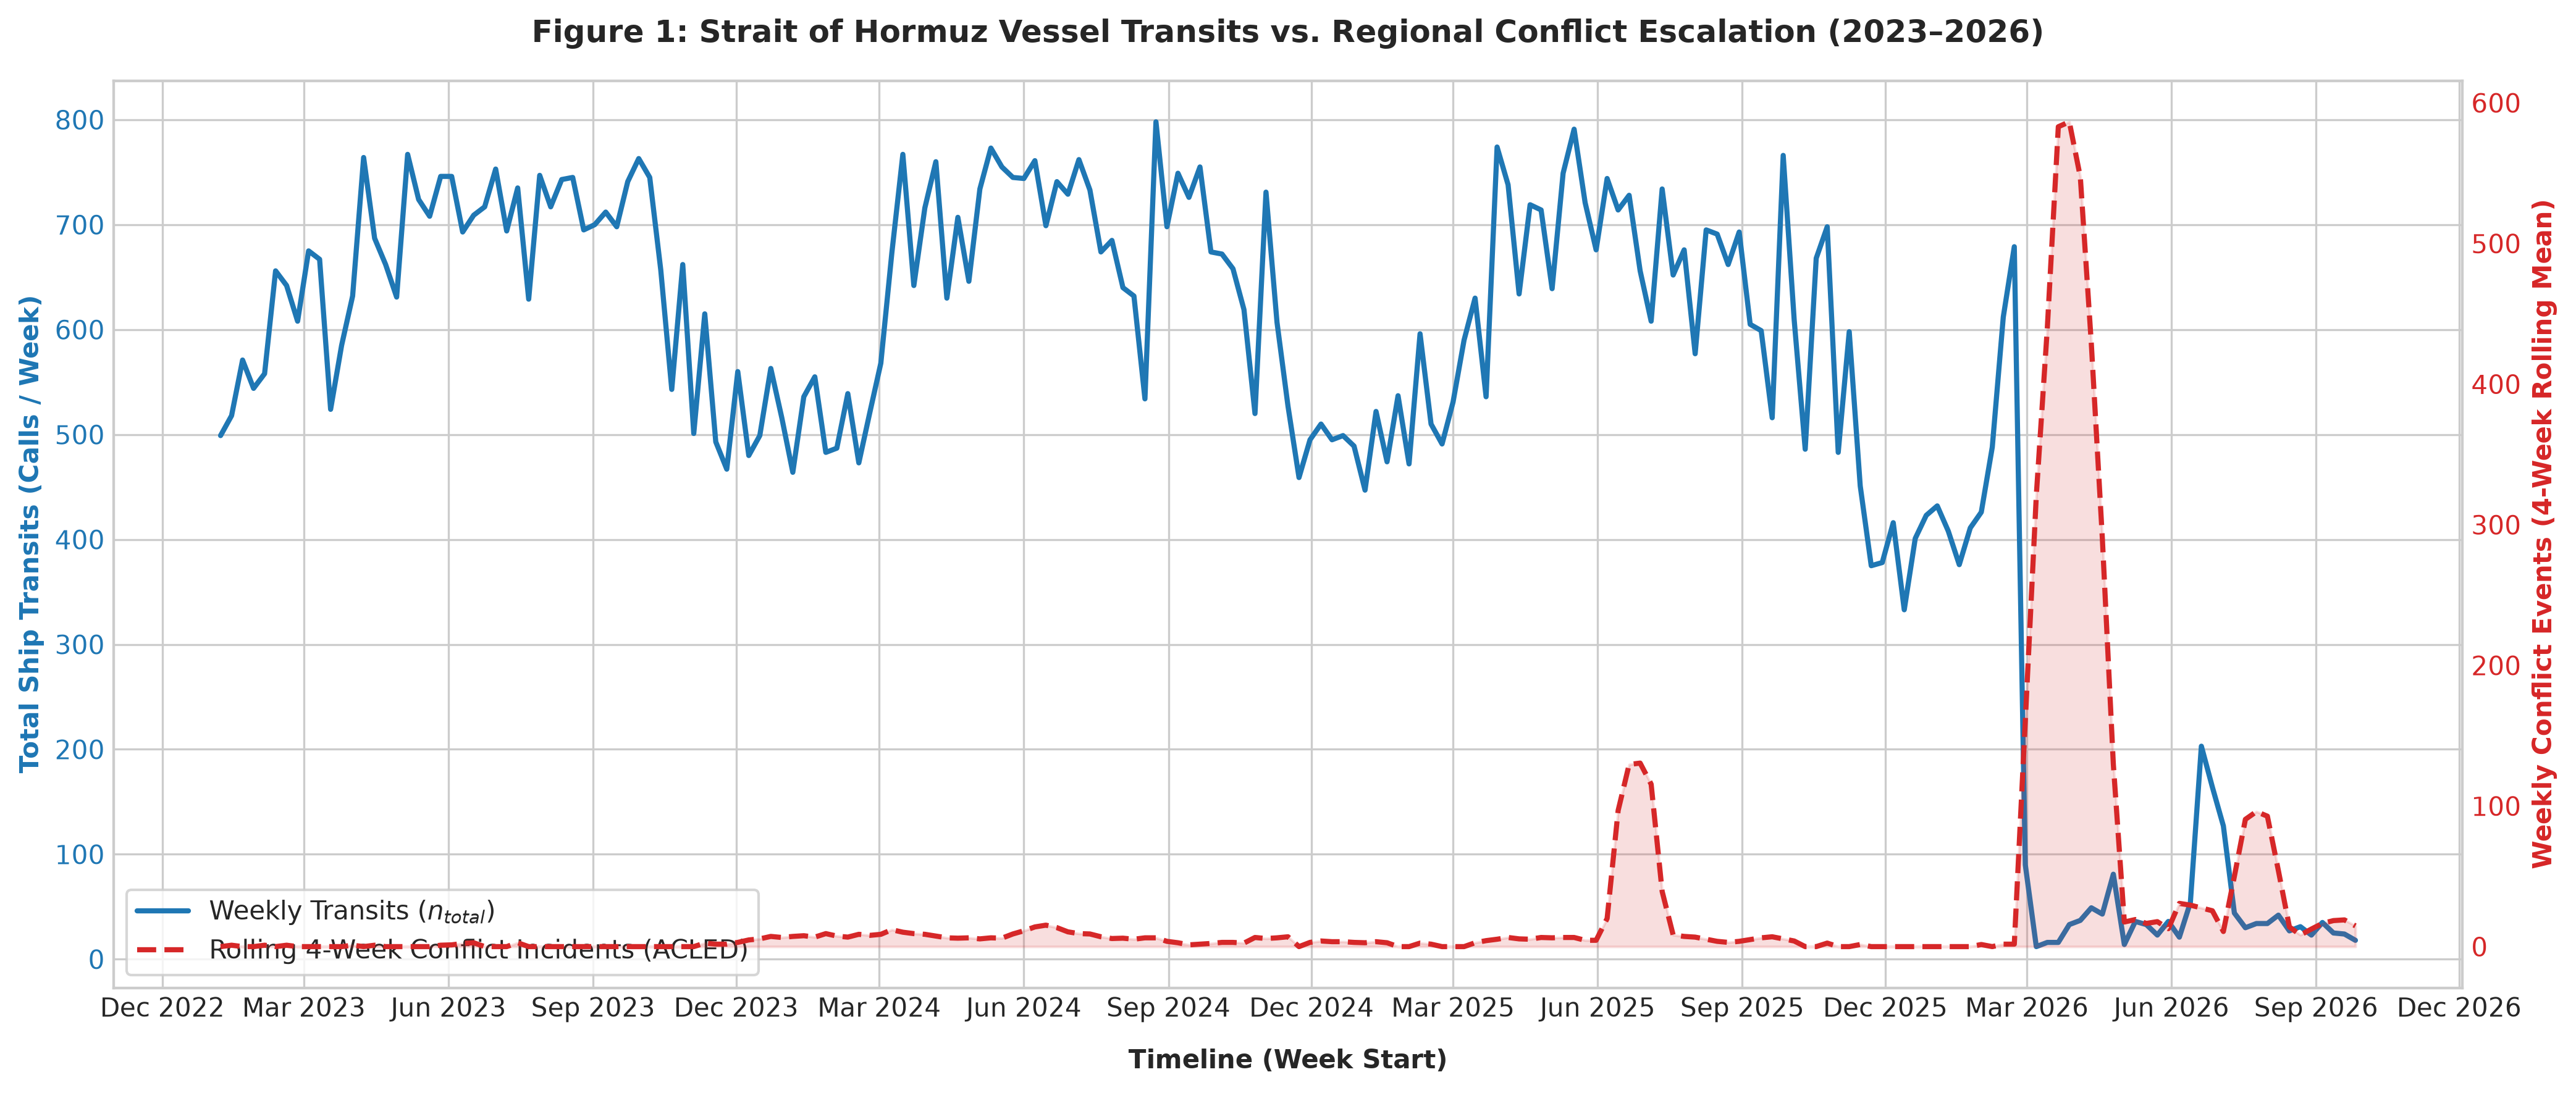

In [2]:
fig, ax1 = plt.subplots(figsize=(14, 6), dpi=300)

# Primary Y-axis: PortWatch Shipping Transits & Deadweight Tonnage
color_transits = '#1f77b4'
color_capacity = '#2ca02c'

line1 = ax1.plot(ds1['week_start'], ds1['n_total'], color=color_transits, linewidth=2, label='Weekly Transits ($n_{total}$)')
ax1.set_xlabel('Timeline (Week Start)', fontweight='bold', labelpad=10)
ax1.set_ylabel('Total Ship Transits (Calls / Week)', color=color_transits, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_transits)
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

# Secondary Y-axis: Conflict Intensity
ax2 = ax1.twinx()
color_conflict = '#d62728## '
line2 = ax2.plot(ds1['week_start'], ds1['conflict_events_rolling4w'], color=color_conflict, linewidth=2, linestyle='--', label='Rolling 4-Week Conflict Incidents (ACLED)')
ax2.fill_between(ds1['week_start'], ds1['conflict_events_rolling4w'], color=color_conflict, alpha=0.15)
ax2.set_ylabel('Weekly Conflict Events (4-Week Rolling Mean)', color=color_conflict, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_conflict)
ax2.grid(False)  # Avoid overlapping gridlines

# Combine legends from both axes
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='lower left', frameon=True)

plt.title('Figure 1: Strait of Hormuz Vessel Transits vs. Regional Conflict Escalation (2023–2026)', pad=15)
fig.tight_layout()
plt.savefig(FIGURES_DIR / "fig1_hormuz_escalation.png")
plt.show()

### Supplementary Analysis for RQ1: Cross-Correlation / Lag Analysis
To determine the exact number of weeks required for traffic to respond to conflict peaks, we compute the Pearson correlation between conflict intensity at time *t* and vessel transits at lag *t+k* (from -8 to +8 weeks).

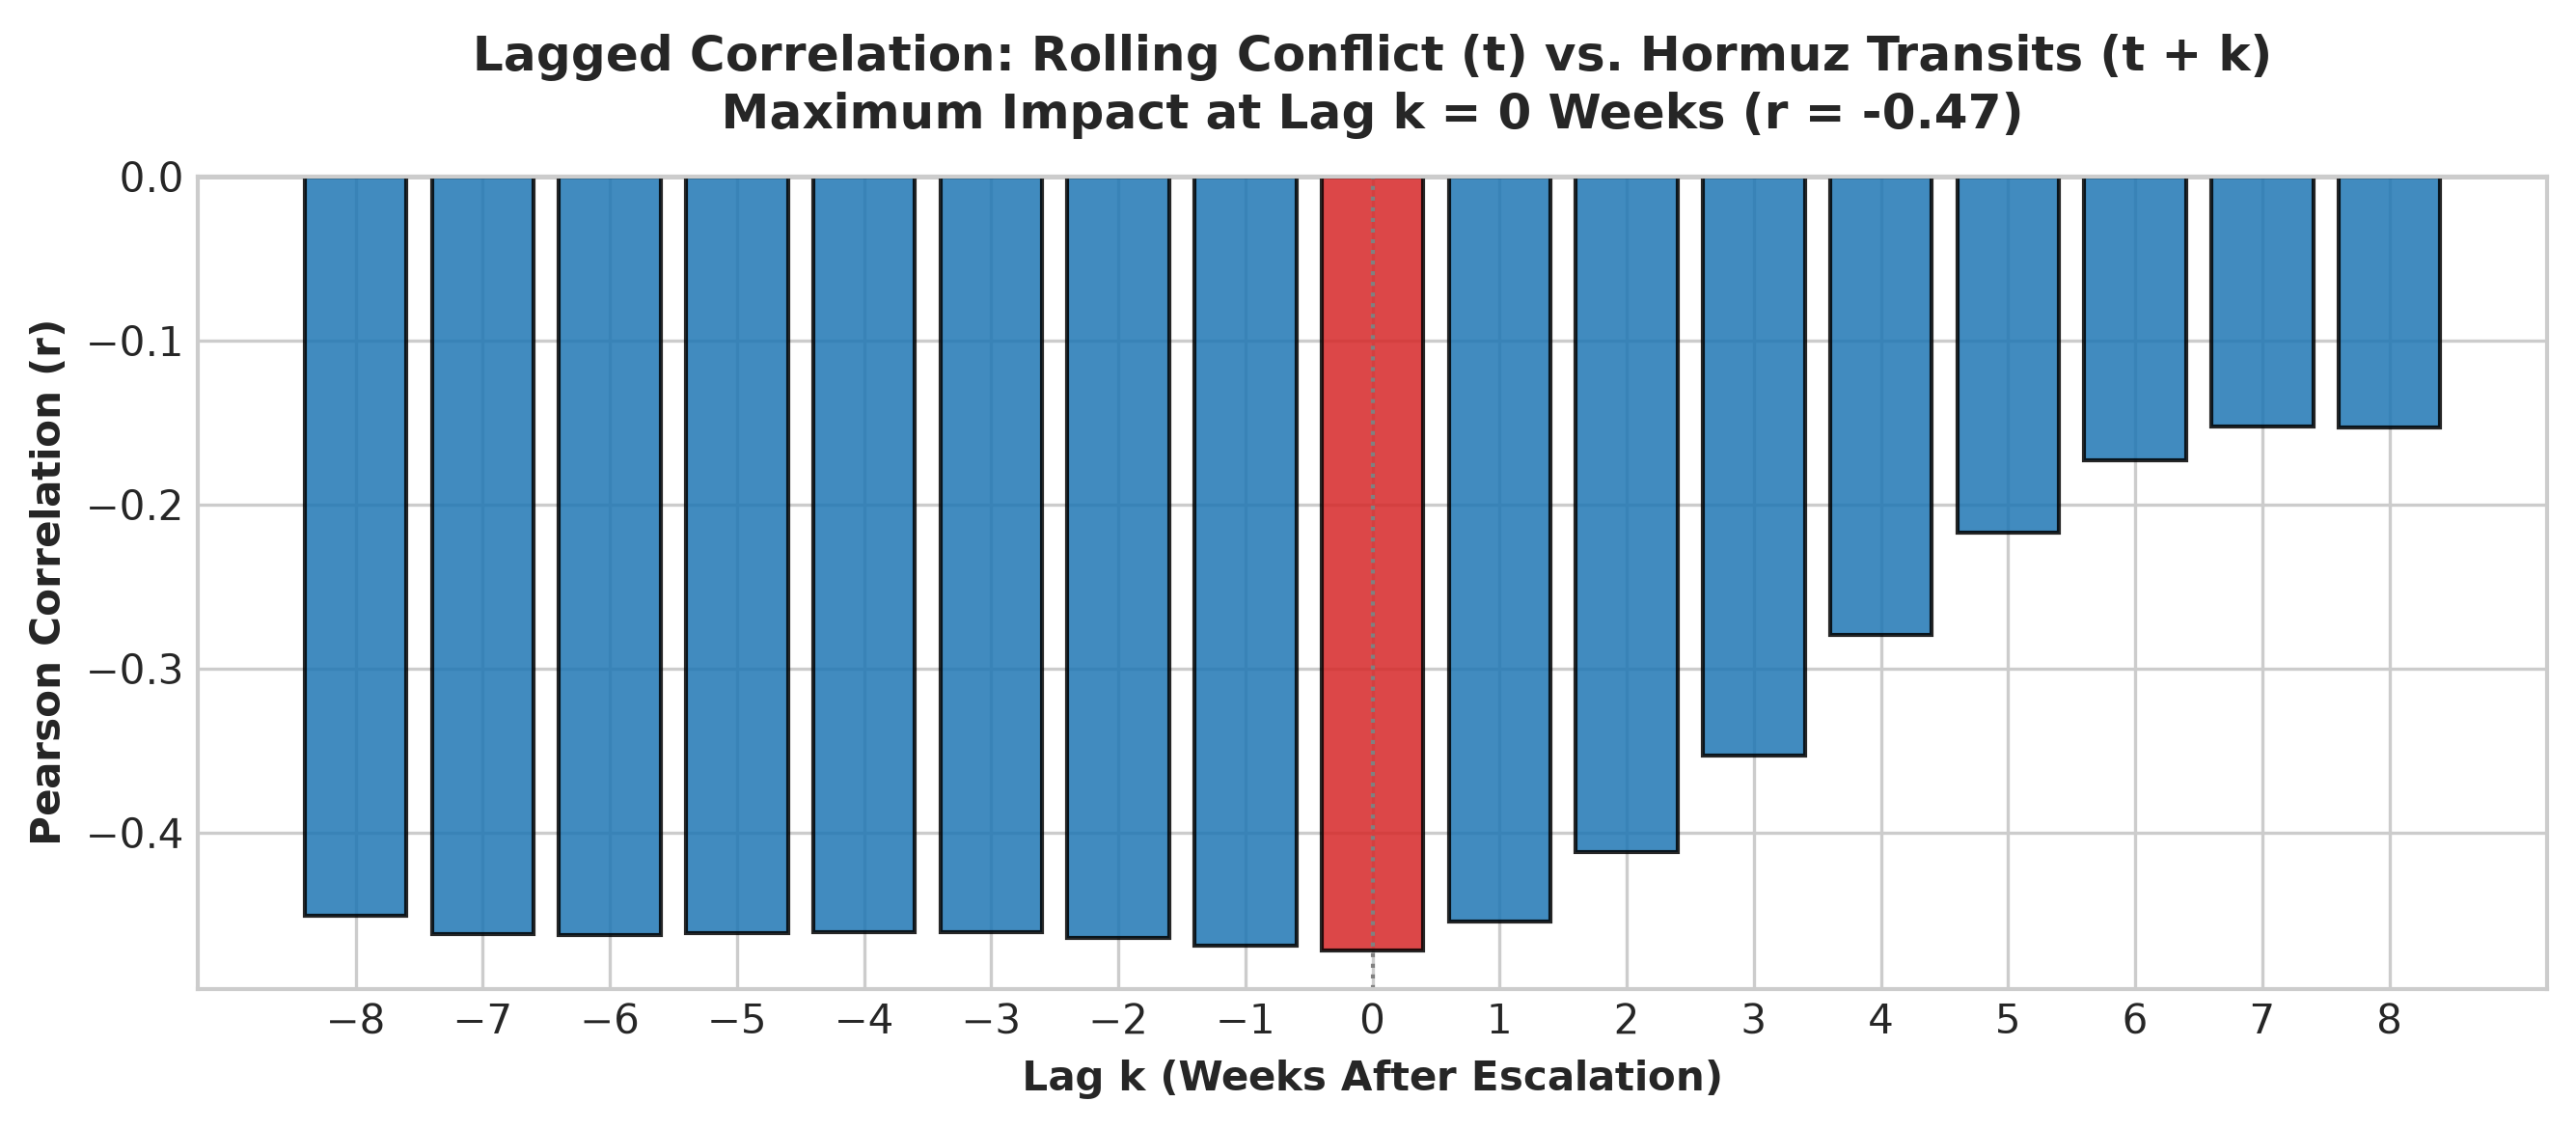

In [3]:
lags = range(-8, 9)
corrs = [ds1['conflict_events_rolling4w'].corr(ds1['n_total'].shift(lag)) for lag in lags]

plt.figure(figsize=(9, 4), dpi=300)
colors = ['#d62728' if c == min(corrs) else '#1f77b4' for c in corrs]
bars = plt.bar(lags, corrs, color=colors, edgecolor='black', alpha=0.85)

min_lag = lags[np.argmin(corrs)]
min_val = min(corrs)
plt.axvline(0, color='gray', linestyle=':', linewidth=1)
plt.axhline(0, color='black', linewidth=0.8)

plt.title(f'Lagged Correlation: Rolling Conflict (t) vs. Hormuz Transits (t + k)\nMaximum Impact at Lag k = {min_lag} Weeks (r = {min_val:.2f})', pad=12)
plt.xlabel('Lag k (Weeks After Escalation)', fontweight='bold')
plt.ylabel('Pearson Correlation (r)', fontweight='bold')
plt.xticks(lags)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig1_sub_hormuz_lag_correlation.png")
plt.show()

## Research Question 2: Around the Cape - Conflict Thresholds for Rerouting
*At what level of conflict intensity does the share of traffic using the Cape of Good Hope, relative to Suez and Bab el-Mandeb, rise significantly above pre-crisis baseline? Does it revert when conflict decreases?*

We evaluate the Cape route traffic share as our primary metric:
\begin{equation}
\text{Cape Share}_t = \frac{\text{Cape}_t}{\text{Cape}_t + \text{Suez}_t + \text{Bab el-Mandeb}_t}
\end{equation}

We visualize this relationship via:
1. Multi-corridor transit volumes over time.
2. Plots of weekly Yemen conflicts (% of incidents as Maritime Events) vs. Cape Route Share to detect the tipping point.
3. A timeline plot showing that even when Maritime Incidents reduce, ships continue to re-route

Addendum: Relationships are statistically tested using a Mann-Whitney-U Test to determine if traffic and conflict levels statistically differ before and during the conflict.

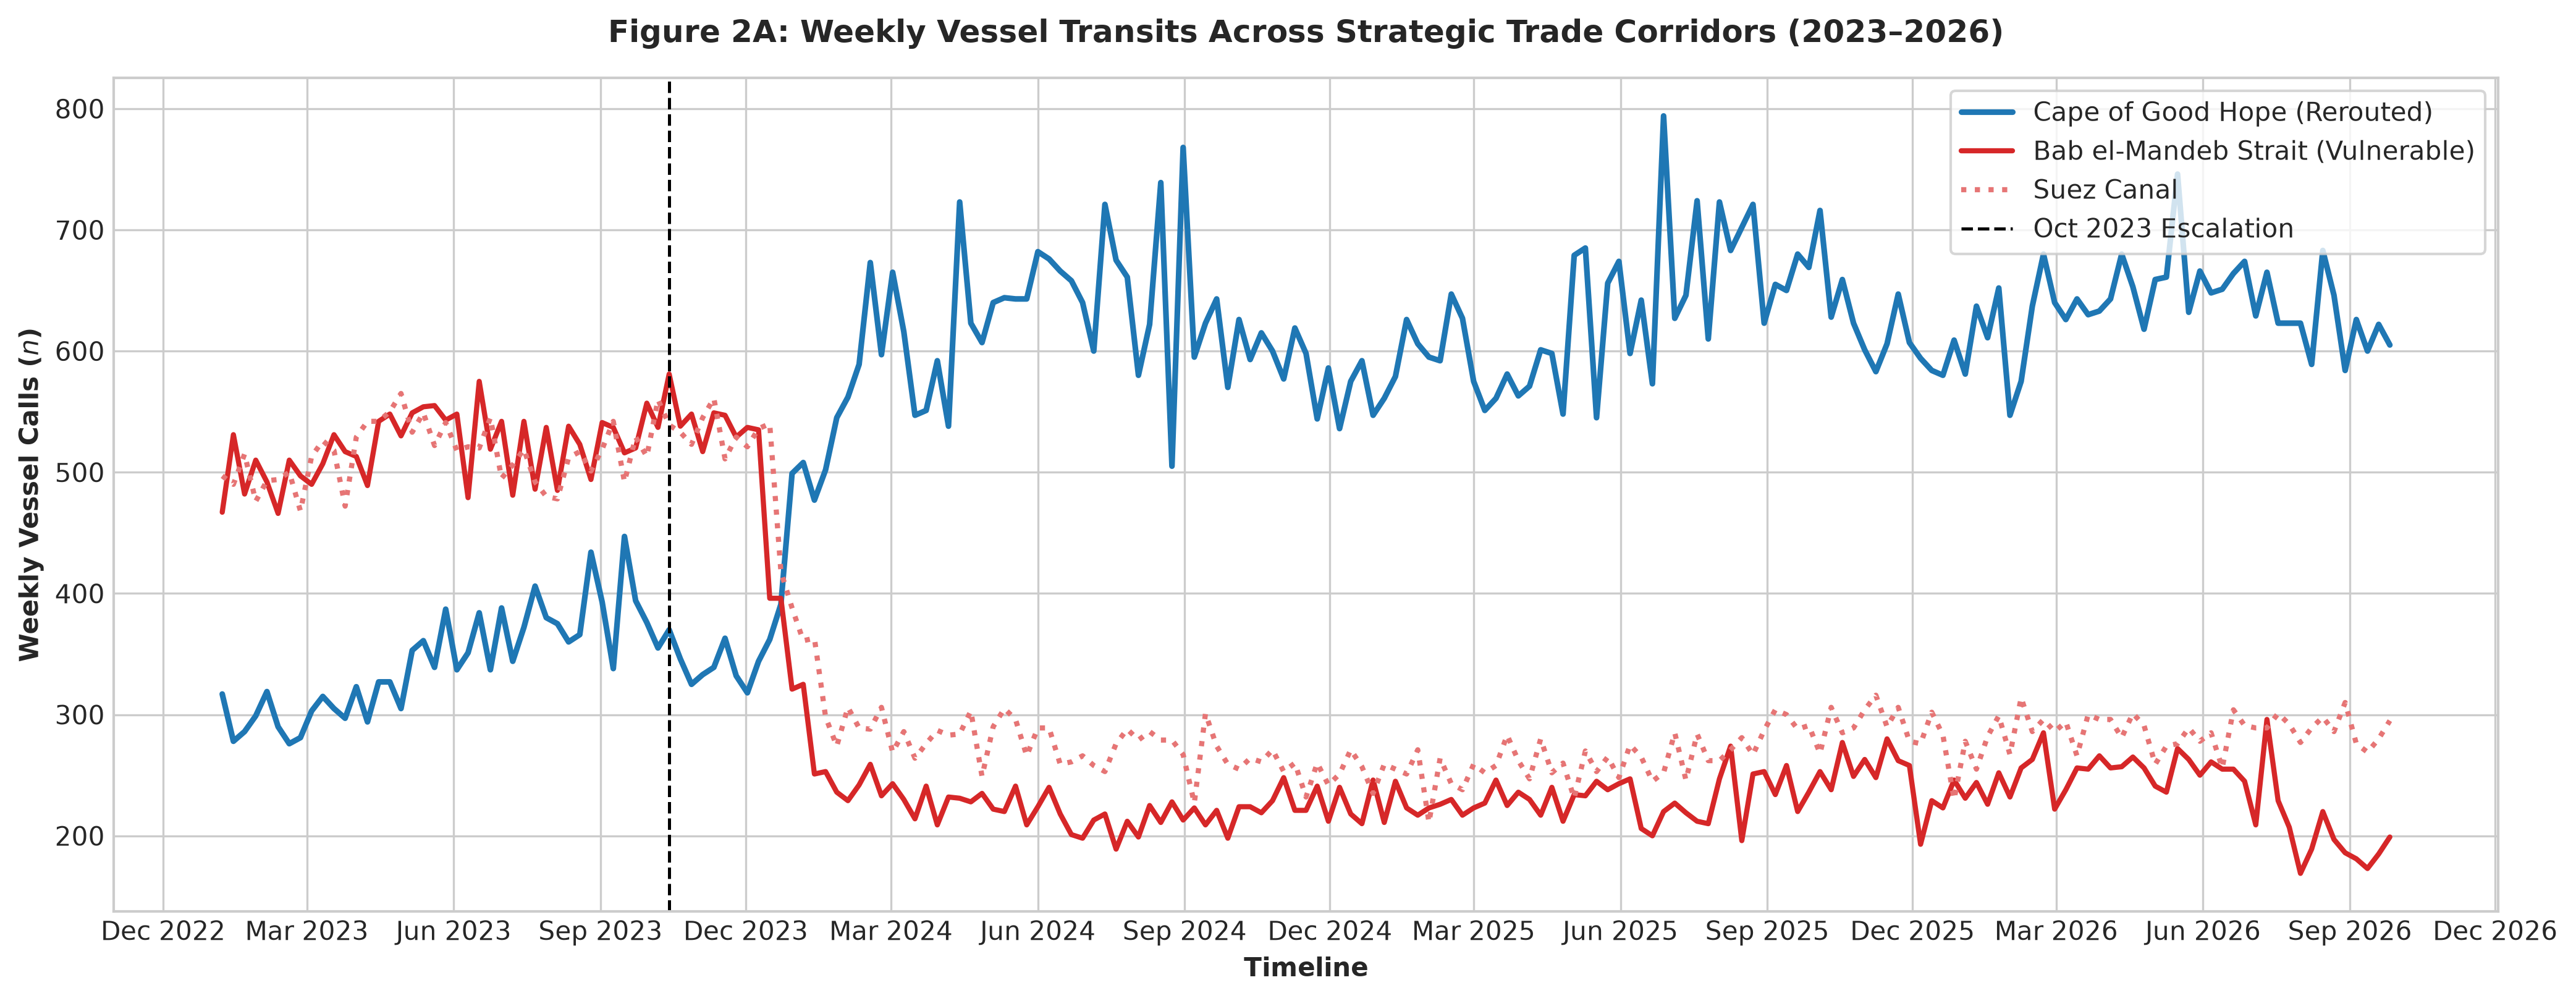

In [31]:
plt.figure(figsize=(14, 5.5), dpi=300)

plt.plot(ds2['week_start'], ds2['Cape of Good Hope'], label='Cape of Good Hope (Rerouted)', color='#1f77b4', linewidth=2.2)
plt.plot(ds2['week_start'], ds2['Bab el-Mandeb Strait'], label='Bab el-Mandeb Strait (Vulnerable)', color='#d62728', linewidth=2)
plt.plot(ds2['week_start'], ds2['Suez Canal'], label='Suez Canal', color='#E67575', linewidth=2, linestyle=':')

# Compute and draw pre-crisis baseline (Jan 2023 - Sep 2023)
baseline_date_end = '2023-10-01'
baseline_cape_share = ds2[ds2['week_start'] < baseline_date_end]['cape_share'].mean()
plt.axvline(pd.to_datetime('2023-10-14'), color='black', linestyle='--', linewidth=1.2, label='Oct 2023 Escalation')

plt.title('Figure 2A: Weekly Vessel Transits Across Strategic Trade Corridors (2023–2026)', pad=14)
plt.xlabel('Timeline', fontweight='bold')
plt.ylabel('Weekly Vessel Calls ($n$)', fontweight='bold')
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig2a_corridor_transits.png")
plt.show()

Testing the Corrolation between Traffic to:
- Suez Canal and the Bab el-Mandeb
- Bab el-Mandeb Straigh tand the Cape of Good Hope

In [56]:
cor_CGH_BeM = stats.pearsonr(ds2['Cape of Good Hope'], ds2['Bab el-Mandeb Strait'])
cor_SC_BeM = stats.pearsonr( ds2['Bab el-Mandeb Strait'], ds2['Suez Canal'])
print(f'Cape of Good Hope vs. Bab el-Mandeb: Correlation: {cor_CGH_BeM[0]}; P-Value: {cor_CGH_BeM[1]}')
print(f'Suez Canal vs. Bab el-Mandeb: Correlation: {cor_SC_BeM[0]}; P-Value: {cor_SC_BeM[0]}')

Cape of Good Hope vs. Bab el-Mandeb: Correlation: -0.900794592003778; P-Value: 7.69774776288281e-72
Suez Canal vs. Bab el-Mandeb: Correlation: 0.9689110000510123; P-Value: 0.9689110000510123


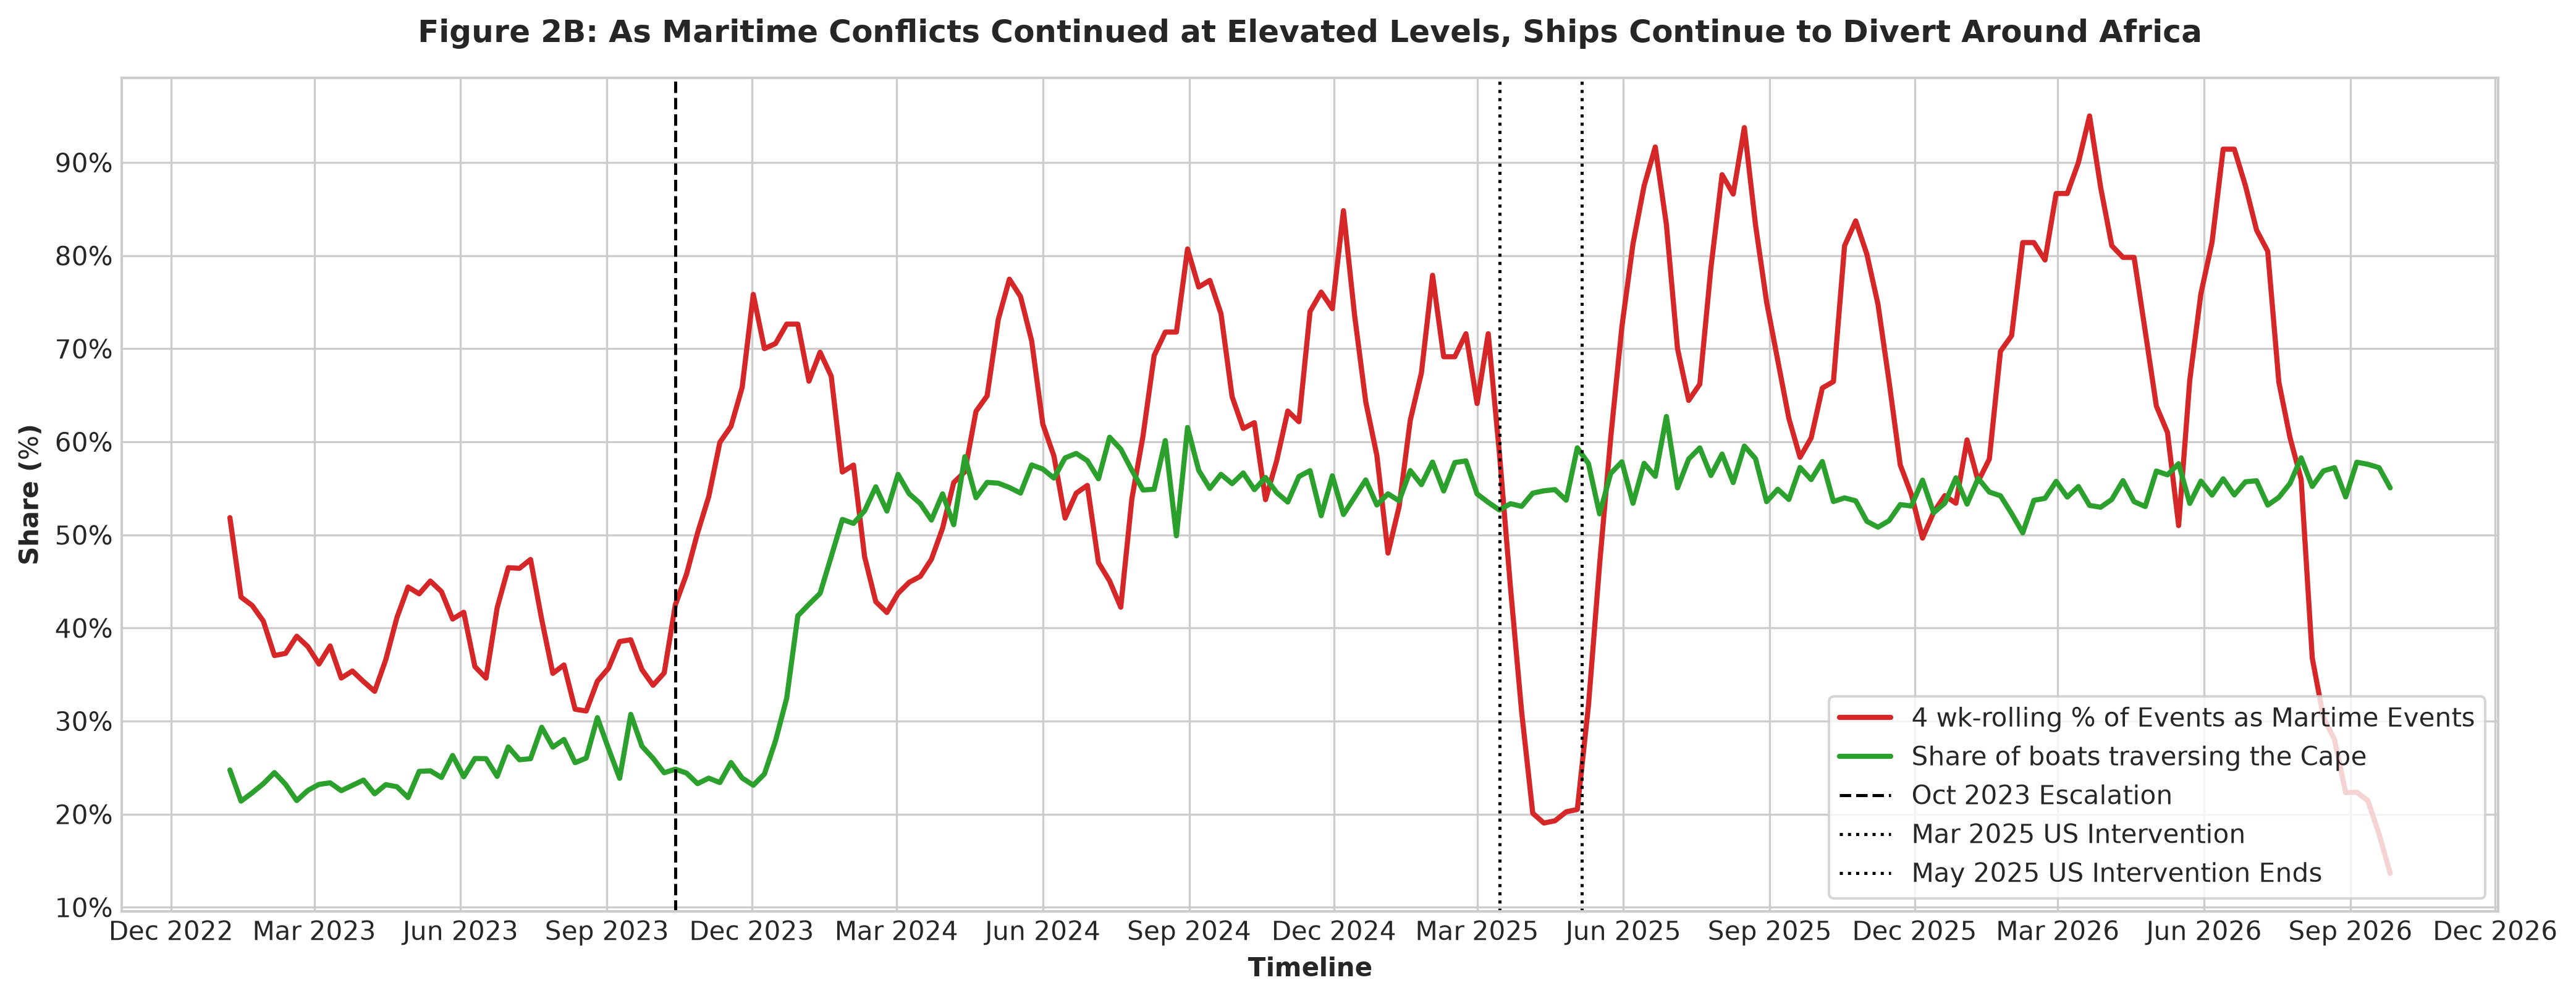

In [33]:
ds2["maritime_events_share"] = ds2["yemen_maritime_sub_events"] / ds2["yemen_conflict_events"]
ds2["share_martime_events_rolling4w"] = ds2["maritime_events_share"].rolling(4, min_periods=1).mean()


plt.figure(figsize=(14, 5.5), dpi=300) #14 x 5.5

## plot time series
plt.plot(ds2['week_start'], ds2["share_martime_events_rolling4w"], label='4 wk-rolling % of Events as Martime Events', color='#d62728', linewidth=2)
plt.plot(ds2["week_start"], ds2["cape_share"], label = "Share of boats traversing the Cape", linewidth=2, color = "#2ca02c")

## plot vertical lines
plt.axvline(pd.to_datetime('2023-10-14'), color='black', linestyle='--', linewidth=1.2, label='Oct 2023 Escalation')
plt.axvline(pd.to_datetime('2025-03-15'), color='black', linestyle=':', linewidth=1.2, label='Mar 2025 US Intervention')
plt.axvline(pd.to_datetime('2025-05-06'), color='black', linestyle=':', linewidth=1.2, label='May 2025 US Intervention Ends')

## Plot extras
plt.legend(frameon=True, loc = "lower right")
plt.title('Figure 2B: As Maritime Conflicts Continued at Elevated Levels, Ships Continue to Divert Around Africa', pad=14)
#Share of Conflict Events occuring in Maritime Environments, and Resulting Diversions Around the Cape of Good Hope
plt.xlabel('Timeline', fontweight='bold')
plt.ylabel('Share ($\\%$)', fontweight='bold')
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
plt.tight_layout()

plt.show()

## should make comment that delay of % going to cape is time lag from switiching directions


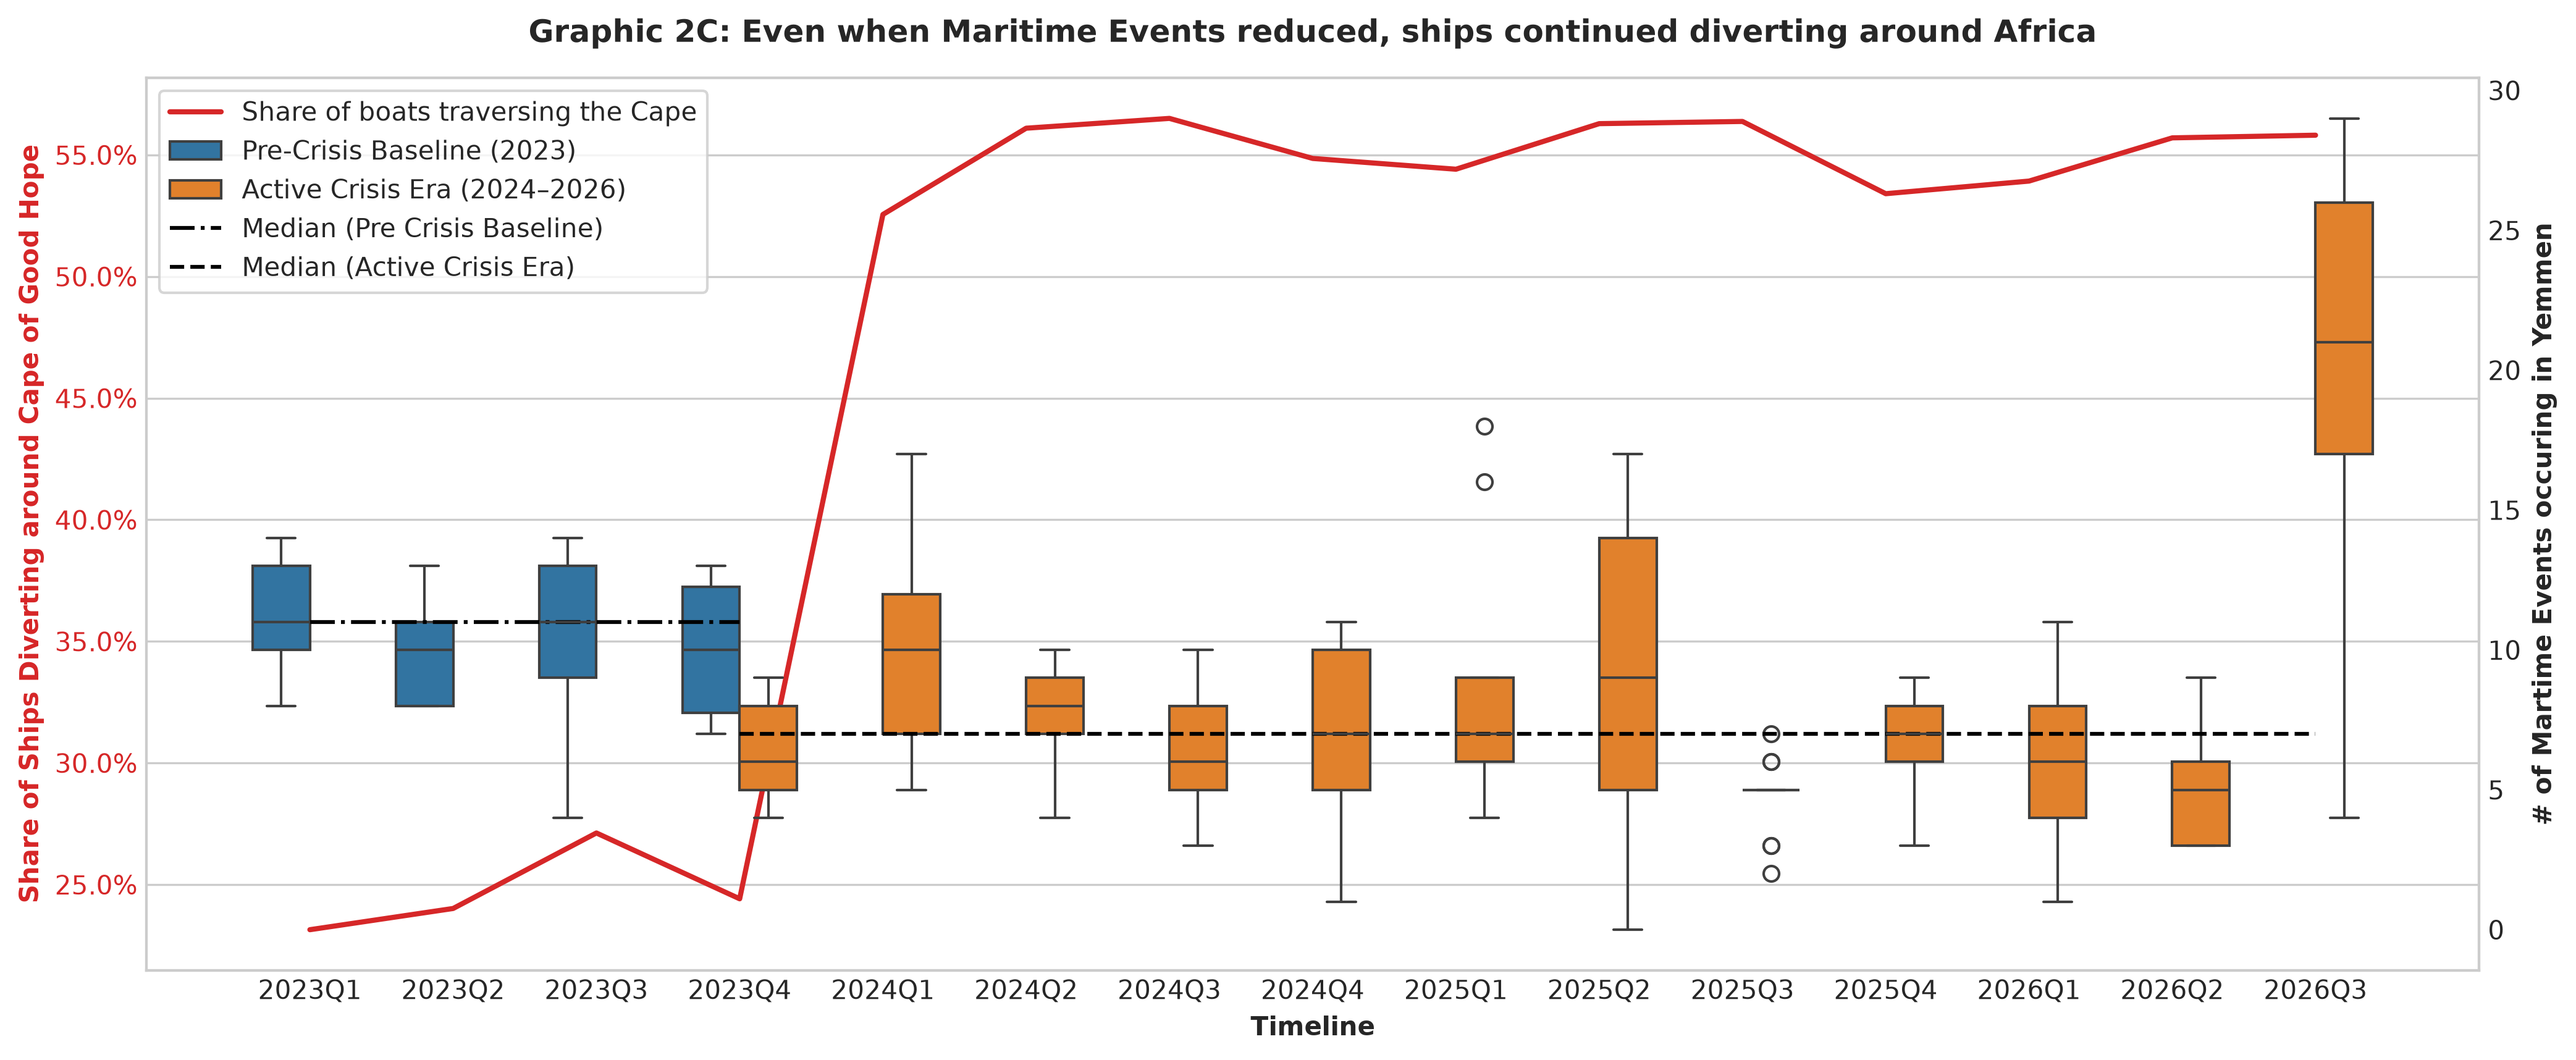

In [51]:
fig, ax1 = plt.subplots(figsize=(14, 5.5), dpi=300)
ds2['Period'] = np.where(ds2['week_start'] < '2023-11-01', 'Pre-Crisis Baseline (2023)', 'Active Crisis Era (2024–2026)')
ds2["quarter"] = ds2["week_start"].dt.to_period("Q").astype(str)

## aggregate on quarterly basis
median_cape_share_quarterly = ds2.groupby("quarter")["cape_share"].median()
median_martime_events = ds2.groupby("quarter")["yemen_maritime_sub_events"].median()

#Red Line Plot
colour_ax1 = "#d62728"
ax1.plot(ds2["quarter"].unique(),
         median_cape_share_quarterly,
         label = "Share of boats traversing the Cape",
         linewidth=2,
            linestyle = "-",
         color = colour_ax1)

#ax1.set_ylim(0, 0.7)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))
ax1.set_ylabel('Share of Ships Diverting around Cape of Good Hope', color=colour_ax1, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=colour_ax1)
ax1.set_xlabel("Timeline", fontweight="bold")
ax1.grid(axis='x')


## Plot Boxplot
ax2 = ax1.twinx()
sns.boxplot(x = ds2["week_start"].dt.to_period("Q").astype(str), y = ds2["yemen_maritime_sub_events"], hue = ds2["Period"], dodge=True)
ax2.set_ylabel('# of Martime Events occuring in Yemmen', fontweight='bold')
ax2.get_legend().remove() # remove the legend as it overlaps with legend produced across entire plot
ax2.grid(False)

## set horizontal medians for boxplot
median_yemen_martime_events_period = ds2.groupby("Period")["yemen_maritime_sub_events"].median()
ax2.hlines(median_yemen_martime_events_period.iloc[1], label = "Median (Pre Crisis Baseline)", xmin=0, xmax = 3, color='#000000', linestyle='-.')
ax2.hlines(median_yemen_martime_events_period.iloc[0], label = "Median (Active Crisis Era)", xmin=3, xmax=14, color='#000000', linestyle='--')

plt.tight_layout()
plt.title('Graphic 2C: Even when Maritime Events reduced, ships continued diverting around Africa', pad=14)

#legend
handels1, labels1 = ax1.get_legend_handles_labels()
handels2, labels2 = ax2.get_legend_handles_labels()
plt.legend(handels1 + handels2, labels1 + labels2, loc='upper left', frameon=True)

plt.show()

### Supplementary Analysis Question 2: Testing statistical significance
- Are changes in Maritime Conflict Events (in Yemmen) statistically significant prior to and during the conflict?
- Are changes in the share of Ships Diverting to the Cape of Good Hope statistically significant prior to and during the conflict?

In [20]:
martime_pre_crisis = ds2[ds2['Period'] == 'Pre-Crisis Baseline (2023)']
martime_crisis_era = ds2[ds2['Period'] == 'Active Crisis Era (2024–2026)']

print(f"PreCrisis Wks: {len(martime_pre_crisis)}; Crisis Wks:{len(martime_crisis_era)}")


#yemen_maritime_sub_events
print('Are changes in Maritime Conflict Events statistically significant between Pre-Crisis and Active Era periods?')
statistic, pval = stats.mannwhitneyu(martime_crisis_era['yemen_maritime_sub_events'], martime_pre_crisis['yemen_maritime_sub_events'])
print(f"P-Value: {float(pval)}") #is significant

print("\n")
#cape_share
print('Are changes in Maritime Traffic at the Cape of Good Hope statistically significant between Pre-Crisis and Active Era periods?')
statistic_cape, pval_cape = stats.mannwhitneyu(martime_crisis_era['cape_share'], martime_pre_crisis['cape_share'])
print(f"P-Value: {float(pval_cape)}") #is significant

PreCrisis Wks: 43; Crisis Wks:152
Are changes in Maritime Conflict Events statistically significant between Pre-Crisis and Active Era periods?
P-Value: 7.57964159719946e-08


Are changes in Maritime Traffic at the Cape of Good Hope statistically significant between Pre-Crisis and Active Era periods?
P-Value: 1.6815852985534583e-21


## Research Question 3: Who Stays, Who Flees? — Vessel-Type Resilience
*How does weekly transit change differ between container ships, tankers, and dry bulk carriers under High vs. Low conflict conditions? Which vessel type retains the largest share of baseline traffic?*

Using Seaborn, we compare normalized vessel retention ratios:
$$\text{Retention Ratio} = \frac{n_{\text{vessel}, t}}{n_{\text{vessel}, \text{baseline}}}$$
across the Strait of Hormuz and Bab el-Mandeb Strait under different conflict regimes.

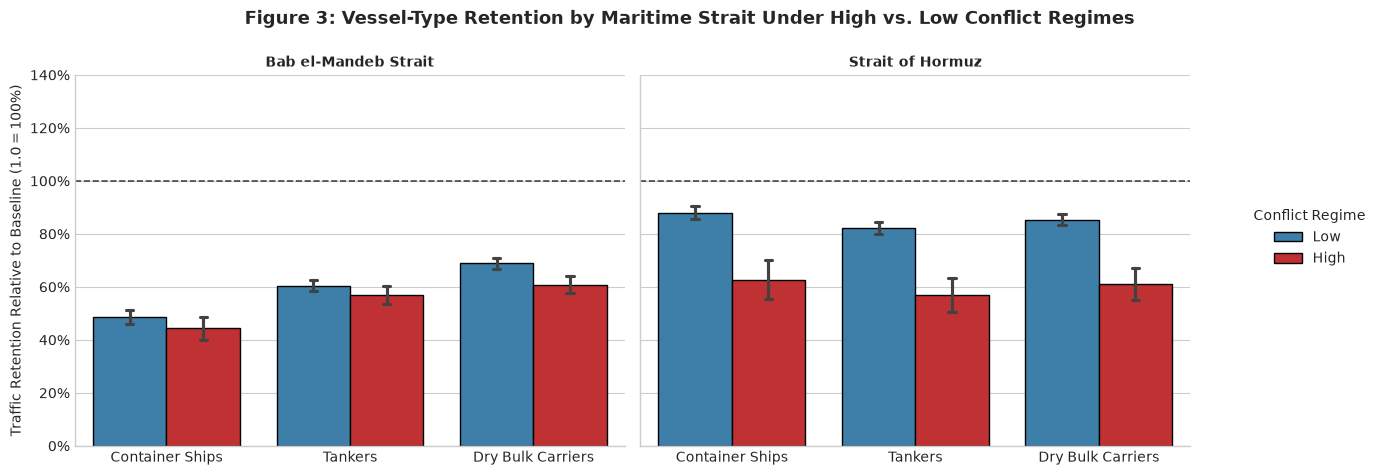

In [4]:
# Melt the retention columns into long format for Seaborn bar plotting
vessel_retention = ds3.melt(
    id_vars=['portname', 'conflict_intensity_level'],
    value_vars=['retention_container', 'retention_tanker', 'retention_dry_bulk'],
    var_name='Vessel Type',
    value_name='Retention Ratio'
)

# Clean labels for presentation
vessel_retention['Vessel Type'] = vessel_retention['Vessel Type'].replace({
    'retention_container': 'Container Ships',
    'retention_tanker': 'Tankers',
    'retention_dry_bulk': 'Dry Bulk Carriers'
})

g = sns.catplot(
    data=vessel_retention,
    x='Vessel Type',
    y='Retention Ratio',
    hue='conflict_intensity_level',
    col='portname',
    kind='bar',
    palette={'Low': '#2b83ba', 'High': '#d7191c'},
    height=5,
    aspect=1.2,
    edgecolor='black',
    errorbar='se',
    capsize=0.08
)

g.set_axis_labels("", "Traffic Retention Relative to Baseline ($1.0 = 100\\%$)")
g.set_titles(col_template="{col_name}", weight='bold')

# Add 1.0 baseline reference line to all subplots
for ax in g.axes.flat:
    ax.axhline(1.0, color='black', linestyle='--', linewidth=1.2, alpha=0.7)
    ax.set_ylim(0, 1.4)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

g._legend.set_title("Conflict Regime")
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle('Figure 3: Vessel-Type Retention by Maritime Strait Under High vs. Low Conflict Regimes', fontsize=13, weight='bold')

plt.savefig(FIGURES_DIR / "fig3_vessel_resilience.png", dpi=300, bbox_inches='tight')
plt.show()

In [5]:
# Summary table for report discussion
summary_table = ds3.groupby(['portname', 'conflict_intensity_level'])[['retention_container', 'retention_tanker', 'retention_dry_bulk']].mean() * 100
summary_table = summary_table.round(1).rename(columns={
    'retention_container': 'Container Retention (%)',
    'retention_tanker': 'Tanker Retention (%)',
    'retention_dry_bulk': 'Dry Bulk Retention (%)'
})

display(summary_table)
summary_table.to_csv("figures/table_vessel_retention_summary.csv")

Container Retention (%)  \
portname             conflict_intensity_level                            
Bab el-Mandeb Strait High                                         44.4   
                     Low                                          48.7   
Strait of Hormuz     High                                         62.6   
                     Low                                          87.9   

                                               Tanker Retention (%)  \
portname             conflict_intensity_level                         
Bab el-Mandeb Strait High                                      56.9   
                     Low                                       60.4   
Strait of Hormuz     High                                      56.9   
                     Low                                       82.2   

                                               Dry Bulk Retention (%)  
portname             conflict_intensity_level                          
Bab el-Mandeb Strait High                                        60.8  
                     Low                                         68.8  
Strait of Hormuz     High                                        61.0  
                     Low                                         85.4